# 04 — Gross Rental Yield, Risk Score & Budget Recommender

Computes trailing-12-month **gross rental yield** (`annual rent / purchase price`, winsorized, preferring `New` Ejari contracts over renewals) paired with a composite **Risk Score** combining trailing price volatility, transaction liquidity, and sample confidence.

> **Important**: Gross yield excludes ~4% DLD transfer fees, agency fees, annual Oqood/DEWA/service charges, and vacancy.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

from dfv.analysis.yield_score import compute_yield_and_risk, recommend_areas_for_budget

Active data mode: processed | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/processed


In [2]:
yr_json = data_dir / "analysis" / "yield_risk.json"
if yr_json.exists():
    yr = json.loads(yr_json.read_text(encoding="utf-8"))
else:
    tx = pd.read_parquet(data_dir / "transactions.parquet")
    rents = pd.read_parquet(data_dir / "rent_contracts.parquet")
    yr = compute_yield_and_risk(tx, rents, min_sales=8, min_rents=6)

print("Caveat:", yr["caveat"])
area_df = pd.DataFrame(yr["area_ranking"])
area_df.head(10)

Caveat: Gross rental yield equals annual rent divided by purchase price using trailing 12-month medians. It ignores DLD transfer fees (4%), Oqood/agency fees, service charges, vacancy, and maintenance costs.


,area_name,gross_yield_pct,risk_score,yield_per_risk_score,median_price_aed,median_sale_ppsqm,median_rent_ppsqm,sales_12m_count,rents_12m_count,confidence
0,Jumeirah Village Circle,8.36,18.8,5.140,942093.0,13846.9,1153.4,15147,49,High
1,Al Furjan,9.34,26.8,4.933,1539921.0,12147.7,1126.4,2779,50,High
2,Arabian Ranches,8.31,31.9,4.023,5356538.0,11513.4,949.3,585,21,High
3,Downtown Dubai,6.06,27.2,3.178,3125080.0,28506.5,1718.4,4036,63,High
4,Dubai Creek Harbour,5.57,24.9,3.047,2558220.0,24762.3,1380.2,3428,50,High
5,Jumeirah Lake Towers,7.97,51.2,2.943,1688265.0,17805.2,1412.4,3744,41,High
6,Discovery Gardens,7.98,55.3,2.809,837652.0,12593.8,1003.7,1420,28,High
7,Dubai Hills Estate,5.48,29.8,2.750,2325017.0,23237.9,1269.2,6226,70,High
8,Business Bay,6.36,43.2,2.607,1796582.0,25016.7,1585.5,9602,90,High
9,Damac Hills,6.42,44.8,2.577,1423176.0,15077.8,949.4,1716,38,High


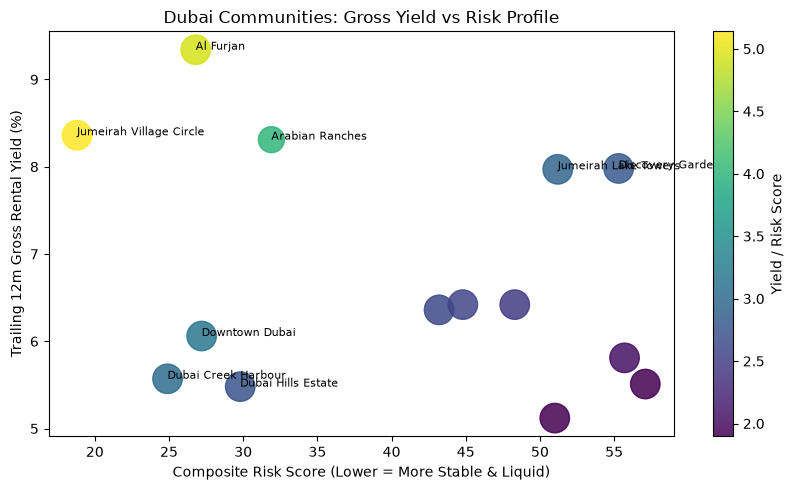

Sample Query — Top 1-Bed Units Under AED 1.5M:


,area_name,property_type,rooms,median_price_aed,median_sale_ppsqm,median_rent_ppsqm,gross_yield_pct,monthly_price_vol,sales_12m_count,rents_12m_count,new_contract_share_pct,used_new_contracts_only,match_level,confidence,risk_score,yield_per_risk_score
0,Jumeirah Village Circle,Unit,1,889200.0,13139.5,1150.7,8.76,0.0388,8069,11,55.0,True,segment,Medium,19.5,5.303
1,Al Furjan,Unit,1,929462.0,12167.0,1209.9,9.94,0.0506,699,4,50.0,True,segment,Medium,26.4,5.292
2,Discovery Gardens,Unit,1,900000.0,12045.1,1000.8,8.31,0.1493,663,4,44.4,True,segment,Medium,55.2,2.927
3,Jumeirah Lake Towers,Unit,1,1495828.0,18265.1,1382.0,7.57,0.1421,1675,6,50.0,True,segment,Medium,51.2,2.797
4,Damac Hills,Unit,1,1048000.0,16427.9,949.4,5.78,0.0926,970,3,33.3,False,segment,Medium,44.1,2.339


In [3]:
if not area_df.empty:
    fig, ax = plt.subplots(figsize=(8.5, 5))
    sc = ax.scatter(
        area_df["risk_score"],
        area_df["gross_yield_pct"],
        s=np.clip(area_df["sales_12m_count"] * 0.6, 50, 450),
        c=area_df["yield_per_risk_score"],
        cmap="viridis",
        alpha=0.85,
    )
    for _, r in area_df.head(8).iterrows():
        ax.annotate(r["area_name"], (r["risk_score"], r["gross_yield_pct"]), fontsize=8)
    ax.set_xlabel("Composite Risk Score (Lower = More Stable & Liquid)")
    ax.set_ylabel("Trailing 12m Gross Rental Yield (%)")
    ax.set_title("Dubai Communities: Gross Yield vs Risk Profile")
    fig.colorbar(sc, label="Yield / Risk Score")
    plt.tight_layout()
    plt.show()

print("Sample Query — Top 1-Bed Units Under AED 1.5M:")
pd.DataFrame(
    recommend_areas_for_budget(
        yr["segment_ranking"], budget_aed=1_500_000.0, rooms=1, property_type="Unit", top_k=5
    )
)